**TAREA:** Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

**IMPORTANTE:** No se admite el uso de modelos de aprendizaje profundo

_Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc._

**TAREA:** La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar,  ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

**IMPORTANTE:** No se admite el uso de modelos de aprendizaje profundo

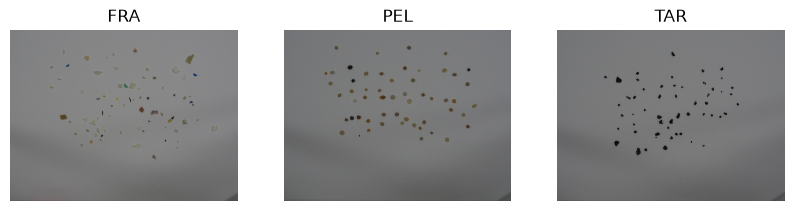

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import csv
import pandas as pd

from sklearn.metrics import confusion_matrix, accuracy_score
import seaborn as sns

# 1. Cargar la imagen de test
img_test = cv2.imread('MPs_test.jpg')
img_test_rgb = cv2.cvtColor(img_test, cv2.COLOR_BGR2RGB)

# 2. Cargar imágenes de entrenamiento
img_F = cv2.imread('fragment-03-olympus-10-01-2020.jpg')
img_P = cv2.imread('pellet-03-olympus-10-01-2020.jpg')
img_T = cv2.imread('tar-03-olympus-10-01-2020.jpg')

img_F_rgb = cv2.cvtColor(img_F, cv2.COLOR_BGR2RGB)
img_P_rgb = cv2.cvtColor(img_P, cv2.COLOR_BGR2RGB)
img_T_rgb = cv2.cvtColor(img_T, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,8))
plt.subplot(1,3,1)
plt.title("FRA")
plt.axis("off")
plt.imshow(img_F_rgb)

plt.subplot(1,3,2)
plt.title("PEL")
plt.axis("off")
plt.imshow(img_P_rgb)

plt.subplot(1,3,3)
plt.title("TAR")
plt.axis("off")
plt.imshow(img_T_rgb)

plt.show()

In [5]:
def segmentar(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5,5), 0)
    
    # En la práctica del cuaderno se usa THRESH_BINARY_INV + OTSU
    _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # Mejorar con morfología
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3,3))
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    contornos, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    return contornos, thresh

def extraer_caracteristicas(contorno, img):
    area = cv2.contourArea(contorno)
    perimetro = cv2.arcLength(contorno, True)

    if area <= 0 or perimetro <= 0:
        return None

    x, y, w, h = cv2.boundingRect(contorno)
    bbox_area = w * h

    compacidad = (perimetro ** 2) / area

    if h > 0:
        aspect_ratio = w / h
    else:
        aspect_ratio = 0

    # Relación entre ejes de la elipse ajustada
    if len(contorno) >= 5:
        elipse = cv2.fitEllipse(contorno)
        (_, _), (eje_menor, eje_mayor), _ = elipse
        if eje_mayor > 0:
            relacion_ejes = eje_menor / eje_mayor
        else:
            relacion_ejes = 0
    else:
        relacion_ejes = 0

    # Solidez y extensión para reforzar la clasificación
    hull = cv2.convexHull(contorno)
    hull_area = cv2.contourArea(hull)
    solidez = area / hull_area if hull_area > 0 else 0
    extension = area / bbox_area if bbox_area > 0 else 0

    mask = np.zeros(img.shape[:2], dtype=np.uint8)
    cv2.drawContours(mask, [contorno], -1, 255, -1)
    
    # Convertimos la imagen a HSV para ser inmunes a los cambios de luz
    img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mean_color = cv2.mean(img_hsv, mask=mask)

    return {
        'area': area,
        'perimetro': perimetro,
        'compacidad': compacidad,
        'aspect_ratio': aspect_ratio,
        'relacion_ejes': relacion_ejes,
        'solidez': solidez,
        'extension': extension,
        'color_H': mean_color[0],
        'color_S': mean_color[1],
    }

def extraer_particulas(img):
    contornos, _ = segmentar(img)
    particulas = []
    
    for c in contornos:
        area = cv2.contourArea(c)
        
        if area < 50:
            continue
        
        feat = extraer_caracteristicas(c, img)
        if feat is None:
            continue
        
        x, y, w, h = cv2.boundingRect(c)
        particulas.append({
            'bbox': (x, y, w, h),
            'features': feat
        })
    
    return particulas

In [6]:
particulas_F = extraer_particulas(img_F)
particulas_P = extraer_particulas(img_P)
particulas_T = extraer_particulas(img_T)

print("FRA:", len(particulas_F))
print("PEL:", len(particulas_P))
print("TAR:", len(particulas_T))

FRA: 161
PEL: 144
TAR: 55


In [8]:
def vector_caracteristicas(feat):
    return np.array([
        feat['compacidad'],
        feat['relacion_ejes'],
        feat['solidez'],
        feat['extension'],
        feat['color_H'],
        feat['color_S']
    ], dtype=float)

# Construcción del conjunto de entrenamiento
X_train = []
y_train = []

for feat in [p['features'] for p in particulas_F]:
    X_train.append(vector_caracteristicas(feat))
    y_train.append('FRA')

for feat in [p['features'] for p in particulas_P]:
    X_train.append(vector_caracteristicas(feat))
    y_train.append('PEL')

for feat in [p['features'] for p in particulas_T]:
    X_train.append(vector_caracteristicas(feat))
    y_train.append('TAR')

X_train = np.array(X_train)
y_train = np.array(y_train)

# Normalización
media = X_train.mean(axis=0)
desviacion = X_train.std(axis=0)
desviacion[desviacion == 0] = 1.0

X_norm = (X_train - media) / desviacion

# Centroide de cada clase
clases = ['FRA', 'PEL', 'TAR']
centroides = {}
for clase in clases:
    centroides[clase] = X_norm[y_train == clase].mean(axis=0)

def clasificar_por_centroides(feat):
    v = vector_caracteristicas(feat)
    v = (v - media) / desviacion
    
    distancias = {}
    for clase in clases:
        distancias[clase] = np.linalg.norm(v - centroides[clase])
    
    return min(distancias, key=distancias.get)

In [9]:
particulas_test = extraer_particulas(img_test)
predicciones = []

for p in particulas_test:
    pred = clasificar_por_centroides(p['features'])
    predicciones.append(pred)

print("Predicciones:", predicciones[:20])
print("Número de partículas detectadas:", len(predicciones))


Predicciones: ['TAR', 'PEL', 'FRA', 'FRA', 'FRA', 'PEL', 'FRA', 'PEL', 'TAR', 'PEL', 'PEL', 'FRA', 'FRA', 'PEL', 'PEL', 'FRA', 'PEL', 'PEL', 'TAR', 'FRA']
Número de partículas detectadas: 39


In [10]:
def iou(b1, b2):
    x1 = max(b1[0], b2[0])
    y1 = max(b1[1], b2[1])
    x2 = min(b1[0] + b1[2], b2[0] + b2[2])
    y2 = min(b1[1] + b1[3], b2[1] + b2[3])

    inter_w = max(0, x2 - x1)
    inter_h = max(0, y2 - y1)
    inter = inter_w * inter_h

    area1 = b1[2] * b1[3]
    area2 = b2[2] * b2[3]
    union = area1 + area2 - inter

    return inter / union if union > 0 else 0.0

# Cargar anotaciones del CSV
with open('MPs_test_bbs.csv', newline='') as f:
    reader = csv.DictReader(f)
    gt = list(reader)

gt_labels = []
gt_bboxes = []

for row in gt:
    x_min = int(row['x_min'])
    y_min = int(row['y_min'])
    x_max = int(row['x_max'])
    y_max = int(row['y_max'])
    
    gt_labels.append(row['label'])
    gt_bboxes.append((x_min, y_min, x_max - x_min, y_max - y_min))

y_real = []
y_pred = []
usadas = set()

for i, p in enumerate(particulas_test):
    bbox_det = p['bbox']
    mejor_idx = None
    mejor_iou = 0.0

    for j, bbox_gt in enumerate(gt_bboxes):
        if j in usadas:
            continue
        valor_iou = iou(bbox_det, bbox_gt)
        if valor_iou > mejor_iou:
            mejor_iou = valor_iou
            mejor_idx = j

    if mejor_idx is not None and mejor_iou > 0.1:
        y_real.append(gt_labels[mejor_idx])
        y_pred.append(clasificar_por_centroides(p['features']))
        usadas.add(mejor_idx)

print("Etiquetas reales:", y_real[:10])
print("Etiquetas predichas:", y_pred[:10])

Etiquetas reales: ['TAR', 'PEL', 'FRA', 'FRA', 'TAR', 'PEL', 'FRA', 'TAR', 'FRA', 'PEL']
Etiquetas predichas: ['TAR', 'PEL', 'FRA', 'FRA', 'FRA', 'PEL', 'FRA', 'PEL', 'TAR', 'PEL']


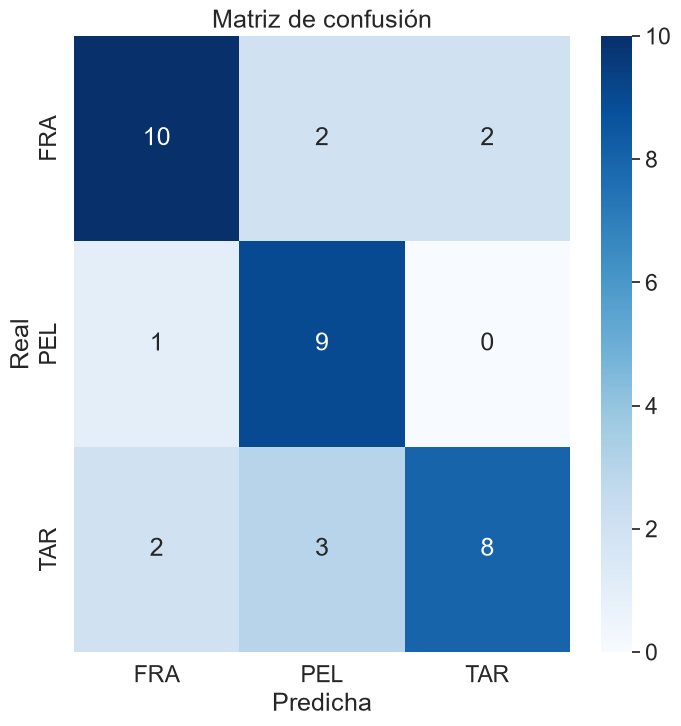

Accuracy: 0.7297297297297297
[[10  2  2]
 [ 1  9  0]
 [ 2  3  8]]


In [11]:
labels = ['FRA', 'PEL', 'TAR']
cm = confusion_matrix(y_real, y_pred, labels=labels)

plt.figure(figsize=(8,8))
sns.set(font_scale=1.5)
ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels)

ax.set_xlabel("Predicha")
ax.set_ylabel("Real")
plt.title("Matriz de confusión")
plt.show()

print("Accuracy:", accuracy_score(y_real, y_pred))
print(cm)